# **Experiment Notebook**

## Weather Hazard Category — Experiment 1: Multinomial Logistic Baseline

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
student_name = "Abhishek Chopda"
student_id = "25611094"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
# Standard data science stack.
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Project toolkit, published to TestPyPI as `mlkit-aby`.
from mlkit_aby.helpers import (
    eda,
    features,
    importance,
    modeling,
    targets,
    timeseries,
    visualization,
    weather,
)

from weather_intelligence.config import (
    RAW_WEATHER_FILE,
    WHC_HORIZON,
    WHC_MODELS_DIR,
    WHC_TRAIN_START,
)

from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# The four hazard classes, in order. Passed explicitly to every metric so
# that a class absent from a split is still reported rather than silently
# dropped -- which matters enormously here, as section C.4 shows.
CLASS_LABELS = [0, 1, 2, 3]
CLASS_NAMES = [targets.WHC_LABELS[c] for c in CLASS_LABELS]

print("Forecast horizon:", WHC_HORIZON, "days")
print("Modelling window starts:", WHC_TRAIN_START)
print("Classes:", CLASS_NAMES)

2026-09-18 15:24:07.514 | INFO     | weather_intelligence.config:<module>:11 - PROJ_ROOT path is: /Users/aby/UTS/AMLA - Sem 4/Assign 2/sydney-weather-intelligence


Forecast horizon: 7 days
Modelling window starts: 2000-01-01
Classes: ['Low Risk', 'Moderate Risk', 'High Risk', 'Extreme Risk']


---
## A. Project Description

In [8]:
business_use_case_description = """
Open Meteo is adding predictive intelligence to its weather platform. This
experiment builds the second of two services: a seven-day-ahead forecast of
the Weather Hazard Category (WHC) for Sydney.

The WHC condenses rainfall, wind gusts, cloud cover, snowfall and
temperature into a hazard severity band: Low, Moderate, High or Extreme
Risk. Where the comfort service answers "is this a pleasant day to be
outdoors", this one answers a different and more consequential question:
"is this a day on which people, infrastructure or transport are at risk".

The seven-day horizon is the defining constraint. A one-day hazard warning
allows people to shelter. A seven-day warning allows organisations to act:
reschedule works, reposition crews, pre-position equipment, alter transport
timetables. The value of the service lies almost entirely in that lead time,
and so does its difficulty.
"""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
business_objectives = """
The objective is to identify hazardous days far enough ahead to be acted
upon, accepting that precision will be sacrificed to achieve it.

The costs of the two error types are wildly asymmetric, far more so than for
the comfort service. A missed hazard -- predicting Low Risk for a day that
turns out to be High or Extreme -- means crews unprepared, works underway in
dangerous conditions, and transport running into a storm. A false alarm
means a day of unnecessary caution: postponed work, idle crews, and some
erosion of trust if it happens often.

The first is materially worse than the second. This has a direct
consequence for how the model should be built and judged: recall on the
hazardous classes matters far more than overall accuracy, and a model
should be tuned to over-warn rather than under-warn.

There is a hard limit on what is achievable, quantified in section C.4.
Extreme Risk days are vanishingly rare in Sydney, and no model trained on
so few examples can be expected to identify them reliably. Establishing
that limit honestly is itself a project objective, because a service that
silently never predicts its most severe class would be actively dangerous
if users assumed otherwise.
"""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
stakeholders_expectations_explanations = """
Predictions are consumed through a REST endpoint accepting a date and
returning the hazard category exactly seven days later.

Direct users are developers integrating the endpoint into operational
scheduling and alerting systems. Indirectly affected are the organisations
acting on those alerts -- councils scheduling outdoor works, transport
operators, event organisers, utilities planning crew availability -- and
ultimately members of the public whose safety depends on those decisions.

Expectations differ sharply from the comfort service in one respect.
Comfort predictions are advisory and a wrong answer costs money. Hazard
predictions may inform safety decisions, and a wrong answer can cost more
than that. The service must therefore be explicit about its limitations
rather than presenting a bare category as authoritative: users need to know
which classes the model can actually detect, and that a seven-day hazard
forecast is a planning aid rather than a warning system. The
/model-metadata endpoint carries the per-class performance figures that make
this visible.
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data

In [14]:
# The same hourly Open-Meteo record used for the comfort experiments. If it
# is absent, regenerate with:
#     uv run python -m weather_intelligence.dataset
hourly = pd.read_csv(RAW_WEATHER_FILE, parse_dates=["time"])

print(f"{len(hourly):,} hourly observations")
print(f"{hourly['time'].min()} to {hourly['time'].max()}")
hourly.head()

227,928 hourly observations
2000-01-01 00:00:00 to 2025-12-31 23:00:00


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2000-01-01 00:00:00,16.2,66,15.5,91,0.0,30.6,0.0
1,2000-01-01 01:00:00,15.9,69,15.1,97,0.0,30.2,0.0
2,2000-01-01 02:00:00,15.6,70,15.0,98,0.0,29.9,0.0
3,2000-01-01 03:00:00,15.5,71,15.0,98,0.0,29.2,0.0
4,2000-01-01 04:00:00,15.5,71,15.5,99,0.0,29.5,0.0


In [15]:
eda.missing_summary(hourly)

,missing_count,missing_percentage
time,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
wind_speed_10m,0,0.0
cloud_cover,0,0.0
precipitation,0,0.0
wind_gusts_10m,0,0.0
snowfall,0,0.0


### C.2 Define Target variable

In [16]:
# The WHI formula is defined on daily values, so hourly observations are
# aggregated first. Note the aggregations relevant to this target: rainfall
# and snowfall are daily totals, and wind gusts are the daily MAXIMUM.
{k: v for k, v in weather.TARGET_DAILY_AGGREGATIONS.items()
 if k in ["precipitation", "wind_gusts_10m", "cloud_cover", "snowfall", "temperature_2m"]}

{'temperature_2m': ('temperature_2m', 'mean'),
 'cloud_cover': ('cloud_cover', 'mean'),
 'precipitation': ('precipitation', 'sum'),
 'wind_gusts_10m': ('wind_gusts_10m', 'max'),
 'snowfall': ('snowfall', 'sum')}

In [17]:
daily = weather.aggregate_to_daily(hourly)
daily["whi"] = targets.weather_hazard_index(daily)
daily["whc"] = targets.weather_hazard_category(daily["whi"])

print(f"{len(daily):,} daily observations")
daily[["date", "precipitation", "wind_gusts_10m", "cloud_cover",
       "snowfall", "temperature_2m", "whi", "whc"]].head()

9,497 daily observations


,date,precipitation,wind_gusts_10m,cloud_cover,snowfall,temperature_2m,whi,whc
0,2000-01-01,0.0,46.8,97.500000,0.0,17.391667,35.383333,1
1,2000-01-02,2.8,34.6,77.208333,0.0,17.500000,30.421667,1
2,2000-01-03,0.1,44.6,36.833333,0.0,19.775000,21.736667,0
3,2000-01-04,2.2,55.1,51.375000,0.0,22.887500,29.360000,1
4,2000-01-05,0.0,47.2,34.250000,0.0,19.179167,22.138333,0


In [18]:
target_definition_explanations = """
The target is the Weather Hazard Category, a four level rating from Low to
Extreme Risk. It is built by combining five hazard scores into a Weather Hazard
Index from 0 to 100, then cutting that index at 25, 50 and 75. The horizon is
exactly seven days.

As with the comfort index, the weather is aggregated to daily values before the
formula is applied, because the formula uses MIN and ABS and so gives a
different answer if applied hourly and averaged afterwards.

The aggregation matters more here. Rainfall and snowfall use daily totals, while
wind gusts use the daily maximum, because a hazard is defined by the worst
moment of the day rather than the average one.

The brief requires predicting the banded category rather than the continuous
index, which discards detail but is what the specification asks for.
"""


In [19]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [20]:
# Hazard components computed separately so each can be inspected.
whi_components = targets.weather_hazard_components(daily)
whi_components.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
rain_hazard,9497.0,0.0666,0.1624,0.000,0.0000,0.0000,0.0467,1.000
wind_hazard,9497.0,0.3942,0.1239,0.126,0.3100,0.3850,0.4640,1.000
cloud_hazard,9497.0,0.4738,0.3004,0.000,0.2196,0.4642,0.7163,1.000
snow_hazard,9497.0,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.000
temperature_hazard,9497.0,0.2007,0.1405,0.000,0.0730,0.1812,0.3238,0.575


In [21]:
target_name = "whc"

daily["whc_label"] = targets.label_weather_hazard_category(daily["whc"])
daily[["date", "whi", "whc", "whc_label"]].head()

,date,whi,whc,whc_label
0,2000-01-01,35.383333,1,Moderate Risk
1,2000-01-02,30.421667,1,Moderate Risk
2,2000-01-03,21.736667,0,Low Risk
3,2000-01-04,29.360000,1,Moderate Risk
4,2000-01-05,22.138333,0,Low Risk


### C.4 Explore Target variable

In [22]:
# The single most important table in this notebook.
distribution = daily["whc"].value_counts().reindex(CLASS_LABELS, fill_value=0)
summary = pd.DataFrame({
    "class": CLASS_LABELS,
    "label": CLASS_NAMES,
    "days": distribution.to_numpy(),
    "share": (distribution / len(daily)).to_numpy(),
})
summary["one_day_every"] = (len(daily) / distribution.replace(0, np.nan)).to_numpy()
summary.round(4)

,class,label,days,share,one_day_every
0,0,Low Risk,5242,0.5520,1.8117
1,1,Moderate Risk,3970,0.4180,2.3922
2,2,High Risk,274,0.0289,34.6606
3,3,Extreme Risk,11,0.0012,863.3636


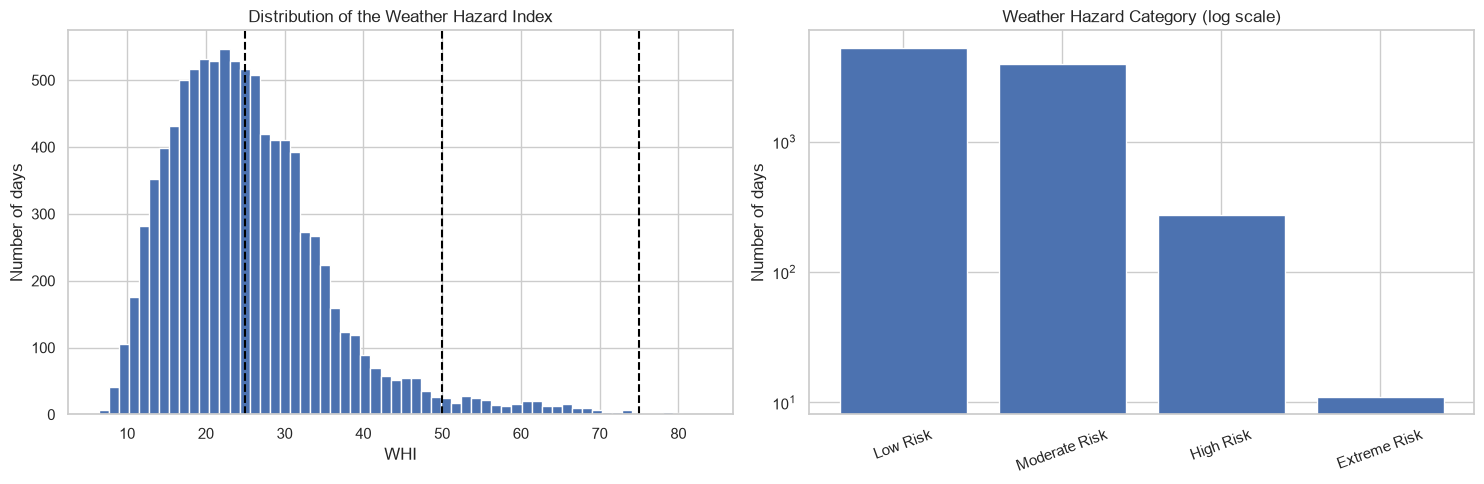

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily["whi"], bins=60, edgecolor="white")
for boundary in [25, 50, 75]:
    axes[0].axvline(boundary, linestyle="--", color="black")
axes[0].set_title("Distribution of the Weather Hazard Index")
axes[0].set_xlabel("WHI")
axes[0].set_ylabel("Number of days")

axes[1].bar(CLASS_NAMES, distribution.to_numpy())
axes[1].set_yscale("log")
axes[1].set_title("Weather Hazard Category (log scale)")
axes[1].set_ylabel("Number of days")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [24]:
# Every Extreme Risk day in 26 years, with the conditions that produced it.
extreme_days = daily[daily["whc"] == 3]
extreme_days[["date", "precipitation", "wind_gusts_10m", "cloud_cover",
              "temperature_2m", "whi"]].round(1).to_string(index=False)

'      date  precipitation  wind_gusts_10m  cloud_cover  temperature_2m  whi\n2007-06-08           63.1            75.6         98.9            13.9 75.7\n2007-06-09           71.9            79.6         95.2            14.2 76.0\n2015-04-21           73.2            83.5         99.5            14.6 77.9\n2016-06-05           85.6            92.5        100.0            17.4 79.6\n2018-11-28           62.2            89.6         97.0            17.8 78.0\n2020-02-09          138.4           102.2        100.0            21.1 80.3\n2020-07-26           76.3            92.2         89.9            13.2 79.1\n2021-08-24           71.4            95.8         99.2            10.7 83.1\n2022-03-08           62.3            82.8         99.7            20.9 75.2\n2022-07-03           52.8            84.2        100.0            15.1 78.0\n2025-07-01           64.7            81.0        100.0            11.4 78.6'

In [25]:
# Does the snowfall term contribute anything at all?
print("Days with any snowfall:", int((daily["snowfall"] > 0).sum()))
print("Maximum attainable WHI given zero snowfall:", 100 * (0.30 + 0.30 + 0.20 + 0.10))
print("Highest WHI observed:", round(daily["whi"].max(), 1))
print()
# How much does each hazard term actually vary?
contribution = pd.DataFrame({
    "std": whi_components.std(),
    "weight": pd.Series(targets.WHI_WEIGHTS),
})
contribution["weighted_std"] = contribution["std"] * contribution["weight"]
contribution.sort_values("weighted_std", ascending=False).round(4)

Days with any snowfall: 0
Maximum attainable WHI given zero snowfall: 90.0
Highest WHI observed: 83.1



,std,weight,weighted_std
cloud_hazard,0.3004,0.2,0.0601
rain_hazard,0.1624,0.3,0.0487
wind_hazard,0.1239,0.3,0.0372
temperature_hazard,0.1405,0.1,0.0141
snow_hazard,0.0000,0.1,0.0000


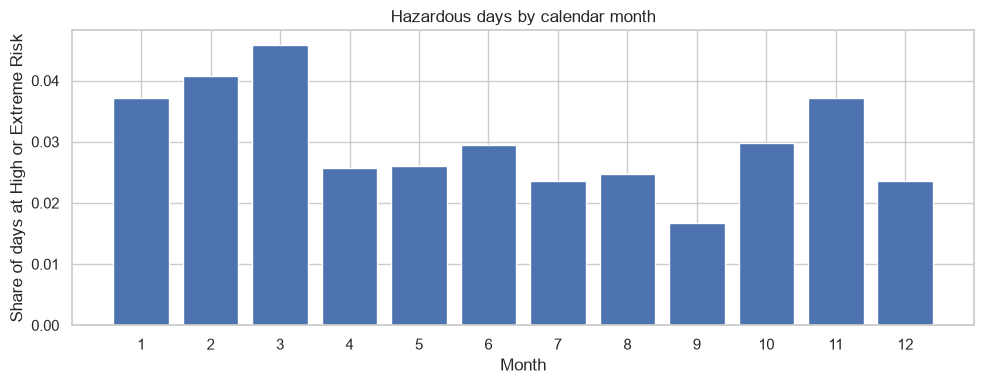

month
1     0.0372
2     0.0408
3     0.0459
4     0.0256
5     0.0261
6     0.0295
7     0.0236
8     0.0248
9     0.0167
10    0.0298
11    0.0372
12    0.0236
Name: whc, dtype: float64

In [26]:
# Hazard is seasonal too, but differently from comfort.
by_month = (
    daily.assign(month=daily["date"].dt.month)
    .groupby("month")["whc"]
    .apply(lambda s: (s >= 2).mean())
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_month.index, by_month.to_numpy())
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Share of days at High or Extreme Risk")
ax.set_title("Hazardous days by calendar month")
plt.tight_layout()
plt.show()

by_month.round(4)

In [27]:
target_distribution_explanations = """
The class distribution is the main problem in this experiment. Across 9,497
days, Low Risk covers 5,242 days and Moderate Risk 3,970, which is 97% of the
record between them. High Risk occurs on 274 days, about 2.9%, and Extreme Risk
on 11 days in 26 years.

This rules out accuracy as a metric, since predicting Low Risk every day would
be 55% accurate while never warning about anything. It also means Extreme Risk
cannot realistically be learned from 11 examples, so it is treated as a
documented limitation rather than a target.

The 11 Extreme days share a clear pattern of heavy rain, severe gusts and near
total cloud together, and are real storms such as the February 2020 east coast
low. Snowfall contributes nothing, since no day in the record has any.
"""


In [28]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `wind_gusts_10m`

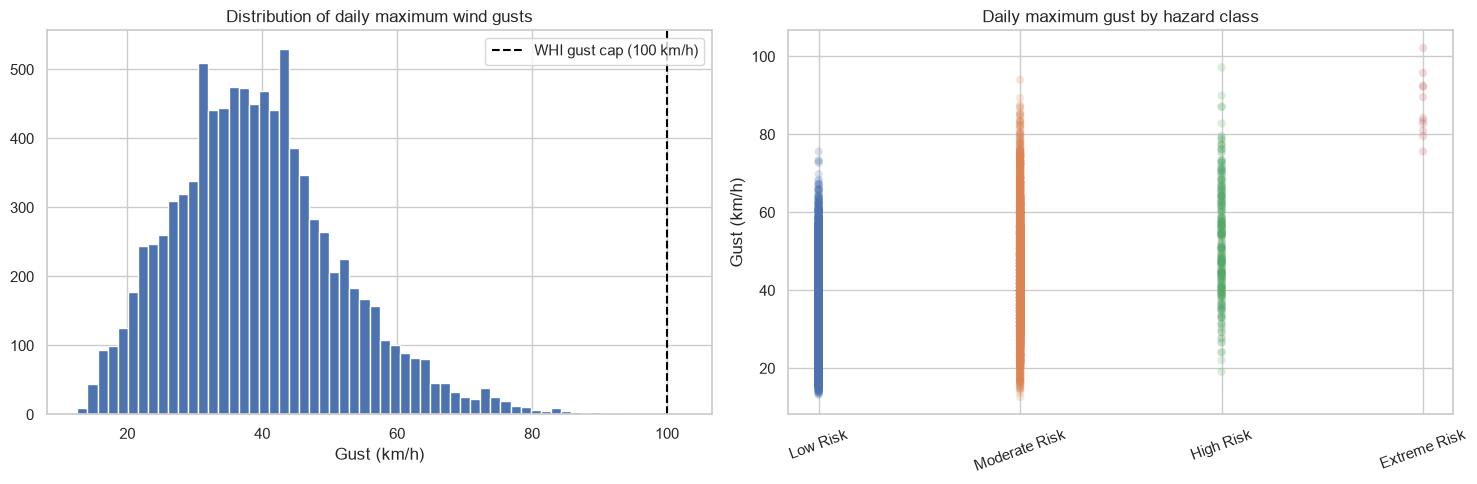

,count,mean,min,max
whc,,,,
0,5242.0,35.3,13.3,75.6
1,3970.0,43.8,12.6,94.0
2,274.0,52.7,19.1,97.2
3,11.0,87.2,75.6,102.2


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily["wind_gusts_10m"], bins=60, edgecolor="white")
axes[0].axvline(100, linestyle="--", color="black", label="WHI gust cap (100 km/h)")
axes[0].set_title("Distribution of daily maximum wind gusts")
axes[0].set_xlabel("Gust (km/h)")
axes[0].legend()

for cls, name in zip(CLASS_LABELS, CLASS_NAMES):
    subset = daily.loc[daily["whc"] == cls, "wind_gusts_10m"]
    if len(subset):
        axes[1].scatter([cls] * len(subset), subset, alpha=0.2, edgecolor="none")
axes[1].set_xticks(CLASS_LABELS)
axes[1].set_xticklabels(CLASS_NAMES, rotation=20)
axes[1].set_ylabel("Gust (km/h)")
axes[1].set_title("Daily maximum gust by hazard class")

plt.tight_layout()
plt.show()

daily.groupby("whc")["wind_gusts_10m"].describe()[["count", "mean", "min", "max"]].round(1)

In [30]:
feature_1_insights = """
Daily maximum wind gusts carry a weight of 0.30, the joint highest, and vary
widely. Most days peak between 25 and 55 km/h, with a tail past 100. The
100 km/h cap is reached only a handful of times in 26 years, so unlike rainfall
this score is almost never saturated and varies across nearly its whole range.

Mean gust speed rises steadily from Low through to Extreme Risk. That is partly
circular, since gusts help define the class, but it confirms the term is doing
real work.

For forecasting the problem is persistence. Gusts change quickly from day to
day, so today's peak says little about the peak in seven days.
"""


In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `precipitation`

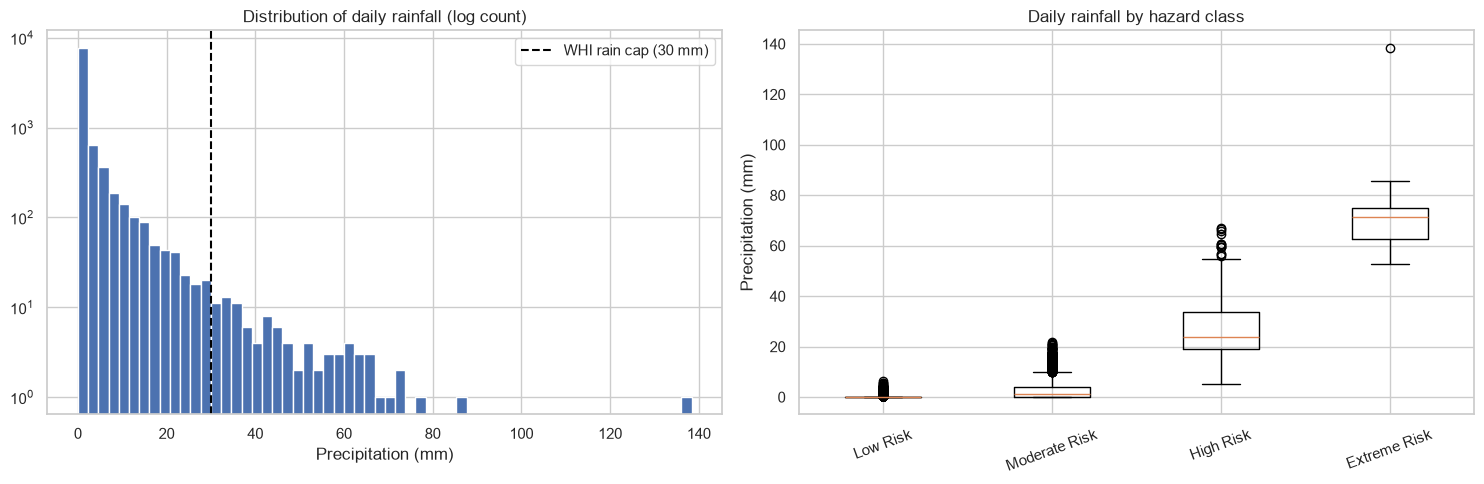

Days at or above the 30 mm cap: 94 (0.99%)


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily["precipitation"], bins=60, edgecolor="white")
axes[0].set_yscale("log")
axes[0].axvline(30, linestyle="--", color="black", label="WHI rain cap (30 mm)")
axes[0].set_title("Distribution of daily rainfall (log count)")
axes[0].set_xlabel("Precipitation (mm)")
axes[0].legend()

axes[1].boxplot(
    [daily.loc[daily["whc"] == c, "precipitation"] for c in CLASS_LABELS],
    tick_labels=CLASS_NAMES,
)
axes[1].set_ylabel("Precipitation (mm)")
axes[1].set_title("Daily rainfall by hazard class")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("Days at or above the 30 mm cap: {} ({:.2%})".format(
    int((daily["precipitation"] >= 30).sum()), (daily["precipitation"] >= 30).mean()))

In [33]:
feature_2_insights = """
Rainfall also carries a weight of 0.30 and is the most awkwardly distributed
variable in the dataset. Just over half of all days record no rain at all, and
the rest fall away steeply.

Its effect on the index is a ramp that stops: above 30 mm the rain score is
capped and further rain changes nothing. About 1% of days reach that cap. The
class boxplots show the expected rise across classes but with wide overlap
between Low and Moderate, because most days in both are dry and it is the other
scores that separate them.

At a seven day horizon this variable is doubly difficult, since it is mostly
zeros and rainfall is among the least persistent weather variables.
"""


In [34]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.n Explore Feature of Interest

> Remaining variables are examined through the correlation analysis in section D.

In [35]:
hazard_variables = ["precipitation", "wind_gusts_10m", "cloud_cover",
                    "temperature_2m", "relative_humidity_2m", "wind_speed_10m"]
eda.numerical_summary(daily[hazard_variables]).round(2)

,count,mean,std,min,25%,50%,75%,max
precipitation,9497.0,2.16,6.15,0.00,0.00,0.00,1.40,138.40
wind_gusts_10m,9497.0,39.42,12.39,12.60,31.00,38.50,46.40,102.20
cloud_cover,9497.0,47.38,30.04,0.00,21.96,46.42,71.62,100.00
temperature_2m,9497.0,17.48,4.13,7.62,13.91,17.60,20.79,30.90
relative_humidity_2m,9497.0,71.70,10.86,23.88,65.04,73.00,79.75,96.04
wind_speed_10m,9497.0,11.39,4.39,3.31,8.15,10.48,13.80,37.39


---
## D. Feature Selection

### D.1 Approach "Correlation with the future target"

In [36]:
# Which of today's variables carry information about the hazard SEVEN days
# from now? Correlation against the future WHI is used rather than the
# banded category, because banding discards the gradations that make a
# correlation meaningful.
future_whi = daily["whi"].shift(-WHC_HORIZON)

seven_day = daily[hazard_variables + ["whi"]].corrwith(future_whi)
same_day = daily[hazard_variables + ["whi"]].corrwith(daily["whi"])

pd.DataFrame({"same_day": same_day, f"{WHC_HORIZON}_days_ahead": seven_day}) \
    .sort_values("same_day", key=abs, ascending=False).round(3)

,same_day,7_days_ahead
whi,1.000,0.063
cloud_cover,0.799,0.063
precipitation,0.746,0.021
wind_gusts_10m,0.476,0.084
wind_speed_10m,0.471,0.059
relative_humidity_2m,0.347,0.036
temperature_2m,0.103,0.136


In [37]:
feature_selection_1_insights = """
This is the most important comparison in the notebook, because it limits what
any model can achieve.

Same day correlations are strong, as they must be, since these variables define
the index. Seven days ahead they almost disappear, including today's hazard
index itself.

The reason is meteorological. A weather system passes through Sydney over two to
four days, so by seven days the system causing today's conditions has gone and
the one that will matter has not formed. Persistence, which is the main
mechanism at one day ahead, is exhausted at seven.

Any usable signal therefore has to come from slower moving information, such as
the time of year and whether the recent period has been unsettled.
"""


In [38]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Variance and redundancy screening"

In [39]:
# A feature that never varies cannot discriminate between classes.
zero_variance = daily[["snowfall"] + hazard_variables].std()
print("Standard deviation of each candidate:")
print(zero_variance.round(4).to_string())
print()
eda.find_highly_correlated_features(daily[hazard_variables], threshold=0.70)

Standard deviation of each candidate:
snowfall                 0.0000
precipitation            6.1483
wind_gusts_10m          12.3938
cloud_cover             30.0381
temperature_2m           4.1288
relative_humidity_2m    10.8585
wind_speed_10m           4.3926



,feature_1,feature_2,correlation
0,wind_gusts_10m,wind_speed_10m,0.836822


In [40]:
feature_selection_2_insights = """
This check removes variables that cannot contribute, either because they never
change or because another variable already carries the same information.

Snowfall has a standard deviation of exactly zero, being 0 mm on all 9,497 days,
so it cannot separate any two days. This also means 10% of the weight specified
for the index is inactive for Sydney, so the highest attainable WHI is 90 rather
than 100.

Wind speed and wind gusts correlate strongly because they measure the same
thing in different ways. Gusts are the variable the formula uses, so they are
kept as primary, but mean wind speed is retained as well because it is smoother
and may survive a seven day horizon better.
"""


In [41]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

## D.z Final Selection of Features

In [42]:
# Variables from which lag and rolling features are derived. Snowfall is
# excluded as constant; humidity and mean wind speed are included as regime
# indicators despite not appearing in the WHI formula.
features_list = [
    "precipitation",
    "wind_gusts_10m",
    "cloud_cover",
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
]

base_features = features_list + ["whi"]
base_features

['precipitation',
 'wind_gusts_10m',
 'cloud_cover',
 'temperature_2m',
 'relative_humidity_2m',
 'wind_speed_10m',
 'whi']

In [43]:
feature_selection_explanations = """
Six weather variables are kept, plus the continuous WHI.

The four variables the formula uses and that vary, rainfall, wind gusts, cloud
cover and temperature, are kept because they define the target. Snowfall is
excluded as constant.

Humidity and mean wind speed are added even though they are not in the formula,
because they describe whether the atmosphere is in a broadly wet or unsettled
state, and section D.1 showed that slower moving information is the only thing
likely to survive seven days. This is a deliberate departure from the comfort
model, where the features were limited to the variables in the index.

The continuous WHI is used rather than the banded category because banding
discards detail that is useful as an input.
"""


In [44]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation: Completeness and continuity

In [45]:
expected_dates = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")

print("Missing values in daily frame:", int(daily.isna().sum().sum()))
print("Missing calendar days:", len(expected_dates.difference(daily["date"])))
print("Duplicate dates:", int(daily["date"].duplicated().sum()))

Missing values in daily frame: 0
Missing calendar days: 0
Duplicate dates: 0


In [46]:
data_cleaning_1_explanations = """
The daily record is complete: no missing values, no missing calendar days
and no duplicate dates across the full 26 years.

Continuity is the critical property here, more so than for the comfort
model, because this target uses a seven-day horizon. Every lag, rolling
window and the target shift itself are positional operations: they move
rows, not dates. A single missing day would mean the "seven days ahead"
target silently became eight days ahead from that point onward, and a
rolling thirty-day window would span thirty-one calendar days. Neither would
raise an error or produce a missing value; both would quietly corrupt the
data in a way that is extremely difficult to detect downstream.

Confirming continuity is what licenses the positional approach. Had gaps
been present, the frame would first have had to be reindexed onto a complete
date range so that the gaps became explicit missing values.
"""

In [47]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation: Target integrity

In [48]:
# The target is produced by code, so it is verified against its definition
# rather than assumed correct.
print("WHI within 0-100:", bool(daily["whi"].between(0, 100).all()))
print("WHC values present:", sorted(daily["whc"].unique().tolist()))

# Every banding boundary must behave as specified: left-closed, right-open.
boundary_check = pd.DataFrame({
    "whi": [0.0, 24.999, 25.0, 49.999, 50.0, 74.999, 75.0, 90.0],
})
boundary_check["whc"] = targets.weather_hazard_category(boundary_check["whi"])
boundary_check

WHI within 0-100: True
WHC values present: [0, 1, 2, 3]


,whi,whc
0,0.000,0
1,24.999,0
2,25.000,1
3,49.999,1
4,50.000,2
5,74.999,2
6,75.000,3
7,90.000,3


In [49]:
data_cleaning_2_explanations = """
The dates run from 2000 to 2025 with no gaps and no duplicates.

This matters more for this target than for the comfort index, because the
horizon is seven days. Every lag, rolling window and the target itself work by
shifting rows rather than dates. If one day were missing from the middle of the
record, the target labelled seven days ahead would quietly become eight days
ahead from that point on, and a thirty day average would cover thirty one
calendar days.

That kind of error produces no warning and no missing values, it simply makes
some rows wrong. Since the dates are complete, shifting rows is safe here.
"""


In [50]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation: Class imbalance strategy

In [51]:
# Rather than resampling the data, imbalance is handled at the model through
# class weights. The weights below are what "balanced" computes.
counts = daily["whc"].value_counts().reindex(CLASS_LABELS, fill_value=0)
balanced_weights = len(daily) / (len(CLASS_LABELS) * counts.replace(0, np.nan))

pd.DataFrame({
    "label": CLASS_NAMES,
    "days": counts.to_numpy(),
    "balanced_weight": balanced_weights.round(1).to_numpy(),
})

,label,days,balanced_weight
0,Low Risk,5242,0.5
1,Moderate Risk,3970,0.6
2,High Risk,274,8.7
3,Extreme Risk,11,215.8


In [52]:
data_cleaning_3_explanations = """
The WHI falls inside its defined 0 to 100 range on every day, and all four
categories appear at least once, so the problem is genuinely four class even
though one class is very rare.

The boundary check confirms the bands behave as specified: a WHI of exactly 25
is Moderate Risk rather than Low. That is not pedantry, because an off by one
error there would misclassify every day landing exactly on a threshold, and with
so few rare class days it could quietly corrupt the counts that matter most.

The weather values are also sensible, with the largest rainfall and strongest
gust both from the February 2020 storm.

No changes are made here. These are checks and nothing needed fixing.
"""


In [53]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Recipe-driven feature construction"

In [54]:
# The experiment-specific decision is which features to build; the package
# assembles them. The recipe is saved inside the model artefact so the
# deployed API builds features identically.
#
# Windows are longer than in the comfort experiment. Section D.1 showed that
# day-specific signal does not survive seven days, so short windows are
# unlikely to help and longer ones describing the prevailing regime are
# more promising.
WHC_RECIPE = {
    "base_variables": base_features,
    "lags": [1, 2, 3, 7],
    "windows": [7, 14, 30, 60],
    "statistics": ["mean", "std"],
    "derived_indices": ["whi"],
    "within_day": True,
    "within_day_lags": [1],
}

daily_features = features.build_daily_features(hourly, WHC_RECIPE)

print(f"{daily_features.shape[1] - 1} features for {len(daily_features):,} days")
print(f"History required per prediction: {features.required_history_days(WHC_RECIPE)} days")
daily_features[["date", "whi", "whi_lag1", "whi_roll7_mean", "whi_roll60_mean"]].tail(5)

117 features for 9,497 days
History required per prediction: 60 days


,date,whi,whi_lag1,whi_roll7_mean,whi_roll60_mean
9492,2025-12-27,23.973333,37.203333,30.217857,29.298250
9493,2025-12-28,30.118333,23.973333,30.279286,29.178139
9494,2025-12-29,17.741667,30.118333,27.915952,28.991417
9495,2025-12-30,21.613333,17.741667,26.960000,28.847167
9496,2025-12-31,31.441667,21.613333,28.474048,28.734556


In [55]:
feature_engineering_1_explanations = """
Lagged values bring earlier days onto the current row, so the model can see the
recent sequence rather than a single day.

For this target they are included mainly as a control. Section D.1 showed that
today's conditions correlate very weakly with the hazard index seven days later,
so a lag of one or three days is unlikely to help much. Keeping them means the
feature importances can confirm that directly, rather than leaving it as an
assumption.

Lags of 1, 2, 3 and 7 days are used, covering a weather system passing through
Sydney and a same day last week comparison. All the shifts are positive, so a
feature can only look backwards.
"""


In [56]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Rolling regime summaries"

In [57]:
rolling_columns = [c for c in daily_features.columns if "_roll" in c]
lag_columns = [c for c in daily_features.columns if "_lag" in c]
print(f"{len(rolling_columns)} rolling features, {len(lag_columns)} lag features")

# Do the longer windows actually carry more seven-day signal than the raw
# values? This is the D.1 question asked of the engineered features.
future_whi = daily_features["whi"].shift(-WHC_HORIZON)
candidates = ["whi", "whi_lag7", "whi_roll7_mean", "whi_roll14_mean",
              "whi_roll30_mean", "whi_roll60_mean",
              "precipitation_roll30_mean", "wind_gusts_10m_roll30_mean"]
daily_features[candidates].corrwith(future_whi).sort_values(key=abs, ascending=False).round(3)

56 rolling features, 38 lag features


wind_gusts_10m_roll30_mean    0.203
whi_roll60_mean               0.158
whi_roll30_mean               0.141
whi_roll14_mean               0.129
whi_roll7_mean                0.105
whi                           0.063
precipitation_roll30_mean     0.058
whi_lag7                      0.054
dtype: float64

In [58]:
feature_engineering_2_explanations = """
Rolling averages summarise the recent past over 7, 14, 30 and 60 days, and
rolling standard deviations describe how settled conditions have been.

These are the features most likely to work at this horizon. Today's hazard index
describes one day whose weather system will have cleared within a week, while a
thirty or sixty day average describes a prevailing state that changes far more
slowly and so has a better chance of still applying in seven days.

The comparison above tests that directly. If longer windows carry more, then
seasonal and longer range features are the way forward. If not, then very little
exists in the local record at this horizon.
"""


In [59]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "Cyclical calendar encoding"

In [60]:
# Section C.4 showed hazardous days cluster seasonally, and the calendar is
# the one input known with certainty for any future date -- which matters
# more at seven days than at one.
year_boundary = daily_features[
    daily_features["date"].isin(
        pd.to_datetime(["2024-12-30", "2024-12-31", "2025-01-01", "2025-01-02"])
    )
]
year_boundary[["date", "day_of_year_sin", "day_of_year_cos"]].round(4)

,date,day_of_year_sin,day_of_year_cos
9130,2024-12-30,-0.0172,0.9999
9131,2024-12-31,-0.0000,1.0000
9132,2025-01-01,0.0172,0.9999
9133,2025-01-02,0.0343,0.9994


In [61]:
feature_engineering_n_explanations = """
Day of year and month are added as sine and cosine pairs, so that 31 December
and 1 January sit next to each other rather than 364 days apart. Two values are
needed because one alone cannot tell spring from autumn.

These features matter more for this target than for the comfort index, for a
reason specific to the horizon. At seven days ahead the recent weather has lost
nearly all of its value, while the calendar has lost none, since the date of a
day next week is known exactly. Section C.4 showed hazardous days cluster in the
cooler, wetter months.

This also makes the seasonal baseline in section J.4 important rather than
decorative.
"""


In [62]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [63]:
# Features were built on the full record so rolling windows are complete
# from the first modelled day. This target uses the entire window.
model_frame = daily_features[
    daily_features["date"] >= WHC_TRAIN_START
].reset_index(drop=True)

EXCLUDED_COLUMNS = {"date", "target_date", "whc", "whc_h7", "whc_label"}
feature_columns = [c for c in model_frame.columns if c not in EXCLUDED_COLUMNS]

print(f"Window: {model_frame['date'].min().date()} to {model_frame['date'].max().date()}")
print(f"{len(model_frame):,} days, {len(feature_columns)} candidate features")
print("Today's WHI retained as an input:", "whi" in feature_columns)

Window: 2000-01-01 to 2025-12-31
9,497 days, 116 candidate features
Today's WHI retained as an input: True


In [64]:
# Split boundaries chosen so that every split contains at least some
# Extreme Risk days. With only eleven in the record this is a real
# constraint on where the boundaries can fall, not a free choice.
VALIDATION_START = "2018-01-01"
TEST_START = "2022-01-01"

supervised = timeseries.make_supervised_frame(
    model_frame, "whc", horizon=WHC_HORIZON
)
supervised = supervised.dropna(subset=feature_columns).reset_index(drop=True)

# The shift introduces missing values and so returns a float column; the
# target is categorical and must be restored to an integer type.
supervised["whc_h7"] = supervised["whc_h7"].astype(int)

train, validation, test = timeseries.chronological_split(
    supervised,
    validation_start=VALIDATION_START,
    test_start=TEST_START,
    horizon=WHC_HORIZON,
)

X_train, y_train = train[feature_columns], train["whc_h7"]
X_val, y_val = validation[feature_columns], validation["whc_h7"]
X_test, y_test = test[feature_columns], test["whc_h7"]

print(f"train      {len(train):>5}   {train['date'].min().date()} -> {train['date'].max().date()}")
print(f"validation {len(validation):>5}   {validation['date'].min().date()} -> {validation['date'].max().date()}")
print(f"test       {len(test):>5}   {test['date'].min().date()} -> {test['date'].max().date()}")

train       6509   2000-02-29 -> 2017-12-24
validation  1454   2018-01-01 -> 2021-12-24
test        1454   2022-01-01 -> 2025-12-24


In [65]:
# Class counts per split. With eleven Extreme days in total, this table
# determines what can and cannot be measured.
split_counts = pd.DataFrame({
    name: part["whc_h7"].value_counts().reindex(CLASS_LABELS, fill_value=0)
    for name, part in [("train", train), ("validation", validation), ("test", test)]
})
split_counts.index = CLASS_NAMES
split_counts

,train,validation,test
Low Risk,3830,706,665
Moderate Risk,2532,686,716
High Risk,143,58,70
Extreme Risk,4,4,3


In [66]:
# The embargo must hold: no training target may fall inside validation.
assert train["target_date"].max() < pd.Timestamp(VALIDATION_START)
assert validation["target_date"].max() < pd.Timestamp(TEST_START)
assert train["date"].max() < validation["date"].min()
assert validation["date"].max() < test["date"].min()
print("Embargo verified: no target crosses a split boundary.")

Embargo verified: no target crosses a split boundary.


In [67]:
data_splitting_explanations = """
The data is split by date, with the earliest period training, the middle
validating and the most recent testing.

Splitting by date rather than at random matters more here than for the comfort
index. Weather is similar from one day to the next, and the Extreme Risk days
occur as consecutive pairs in two cases, so a random split could put 8 June 2007
in training and 9 June 2007 in testing. The model would appear to detect an
extreme event it had already been shown.

The last seven days of each period are removed because their targets fall on the
other side of the boundary.

The boundaries were chosen so that all three splits contain at least some
Extreme Risk days, which is a mild compromise worth acknowledging: with only 11
such days in the record, most other choices would leave a split with none, making
the class unmeasurable there.
"""


In [68]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Standardisation within the model pipeline"

In [69]:
# As with the comfort experiment, scaling is the first stage of a pipeline
# rather than a separate step, so the scaler and model are fitted, saved
# and applied together.
def make_model(C=1.0, class_weight="balanced"):
    """Build an unfitted scaler + multinomial logistic pipeline."""
    return modeling.make_scaled_pipeline(
        LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=5000,
            random_state=RANDOM_STATE,
        )
    )


demonstration = make_model().fit(X_train, y_train)
scaled = demonstration.named_steps["scaler"].transform(X_train)
pd.DataFrame(scaled, columns=feature_columns)[
    ["precipitation", "wind_gusts_10m"]
].describe().loc[["mean", "std"]].round(3)

,precipitation,wind_gusts_10m
mean,0.0,-0.0
std,1.0,1.0


In [70]:
data_transformation_1_explanations = """
Features are standardised as the first stage of the model pipeline.

Logistic regression needs this for two reasons. Its penalty acts on the size of
the coefficients, which depends on each feature's units, so without a common
scale the amount of regularisation applied to rainfall in millimetres and
humidity in percent would differ arbitrarily. It is also fitted by an iterative
solver, which converges slowly when features are on very different scales.

The scaler is fitted on the training split alone and reused unchanged
afterwards. Fitting it on all the data before splitting would encode
information about the test period, which in a time series means encoding the
future. Placing it inside the pipeline enforces this automatically.
"""


In [71]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

---
## H. Save Datasets

In [72]:
data_final_path = "../../data/processed"
Path(data_final_path).mkdir(parents=True, exist_ok=True)
print("Saving WHC modelling datasets to", data_final_path)

Saving WHC modelling datasets to ../../data/processed


In [73]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

In [74]:
# Saved again under target-specific names, so that the comfort and hazard
# datasets do not overwrite one another in the shared processed folder.
for name, frame in [("X_train", X_train), ("y_train", y_train),
                    ("X_val", X_val), ("y_val", y_val),
                    ("X_test", X_test), ("y_test", y_test)]:
    frame.to_csv(f"{data_final_path}/whc_{name}.csv", index=False)
print("Saved WHC-prefixed copies.")

Saved WHC-prefixed copies.


---
## I. Selection of Performance Metrics

In [75]:
help(modeling.evaluate_classification)

Help on function evaluate_classification in module mlkit_aby.helpers.modeling:

evaluate_classification(y_true, y_pred, labels=None) -> dict[str, float]
    Calculate performance metrics for a multiclass classification model.

    Accuracy is reported for completeness but should not be used as the
    headline metric on imbalanced data: a model that always predicts the
    majority class can post a high accuracy while being useless. Macro F1
    and balanced accuracy weight every class equally and expose that
    failure.

    Args:
        y_true: Observed class labels.
        y_pred: Predicted class labels.
        labels: Full list of possible class labels. Supplying this ensures
            classes absent from a given split are still reported, rather
            than silently omitted.

    Returns:
        dict[str, float]:
            Overall accuracy, balanced accuracy, macro and weighted F1,
            and per-class recall and F1 keyed by class label.



In [76]:
# Why accuracy is excluded: the score a model achieves by never predicting
# anything hazardous at all.
naive_always_low = pd.Series([0] * len(y_test))
naive_metrics = modeling.evaluate_classification(y_test, naive_always_low, labels=CLASS_LABELS)

print(f"A model that always predicts 'Low Risk':")
print(f"  accuracy          {naive_metrics['accuracy']:.3f}")
print(f"  balanced accuracy {naive_metrics['balanced_accuracy']:.3f}")
print(f"  macro F1          {naive_metrics['macro_f1']:.3f}")

A model that always predicts 'Low Risk':
  accuracy          0.457
  balanced accuracy 0.250
  macro F1          0.157


In [77]:
performance_metrics_explanations = """
Macro F1 is the headline metric, supported by balanced accuracy and by
per-class recall. Accuracy is reported only to demonstrate why it must not
be used.

The output above makes the case directly. A model that predicts Low Risk for
every day in the test set -- a model containing no information whatsoever --
achieves a respectable accuracy, because Low Risk days are the plurality.
Its balanced accuracy is 0.25 and its macro F1 far lower, because both
metrics average performance across classes rather than across days, so
three classes scoring zero cannot be hidden behind one scoring well.

Per-class recall is reported for every class individually and is the figure
that matters operationally. Recall on High and Extreme Risk answers the
question the service exists to answer: of the genuinely hazardous days, how
many did we flag? Section A established that a missed hazard is far more
costly than a false alarm, which makes recall on the hazardous classes more
important than precision on them. A model that flags fifty days to catch
twenty real hazards may be entirely acceptable; one that flags five and
catches three is not.

Macro F1 is preferred to balanced accuracy as the single headline because it
accounts for precision as well as recall. Balanced accuracy alone can be
driven upwards by indiscriminate over-warning, and with heavy class
weighting that is a real risk rather than a theoretical one.

One caveat applies throughout. Per-class metrics for Extreme Risk are
computed from a handful of test days, so they are extremely unstable: a
single day changing outcome moves the recall by a large fraction. They are
reported for completeness and should not be read as reliable estimates.

A metric that recognised the ordering of the classes -- treating a Low for
Extreme confusion as worse than Low for Moderate -- would fit the problem
better than any of these. The specification requires a standard multiclass
classification, so this is noted as a limitation rather than acted upon, and
the confusion matrix in section J.4 is used to inspect the severity of
misclassifications directly.
"""

In [78]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [79]:
help(modeling.make_scaled_pipeline)

Help on function make_scaled_pipeline in module mlkit_aby.helpers.modeling:

make_scaled_pipeline(estimator, scaler=None) -> sklearn.pipeline.Pipeline
    Chain a scaler and an estimator into a single object.

    Keeping the two together matters at deployment. Scaling and prediction
    are a single operation from the model's point of view: predictions made
    on unscaled inputs, or on inputs scaled using different statistics, are
    wrong rather than merely worse. Bundling them means the saved artefact
    cannot be used incorrectly, because there is no separate scaling step to
    forget or to apply differently.

    Fitting the pipeline also fits the scaler on the training data only, and
    every later call reuses those statistics. That is the correct behaviour
    for a time series: the scaler available at prediction time is the one
    fitted when the model was trained.

    Args:
        estimator:
            Any scikit-learn estimator, already configured with its
          

In [80]:
algorithm_selection_explanations = """
This experiment uses multinomial logistic regression with balanced class
weights, chosen as a baseline rather than as the expected final model. It is the
classification counterpart of the ridge regression used for the comfort
baseline, which keeps the two tracks comparable.

It handles the imbalance directly, since class weights rescale each class's
contribution in inverse proportion to its frequency. It also produces class
probabilities rather than bare labels, which leaves open the option of tuning
the decision threshold towards over warning. And it is fast and interpretable,
so it establishes a defensible floor cheaply.

Its limitation is that it fits straight boundaries, while a hazardous day is a
combination of conditions occurring together, which a tree represents naturally.
"""


In [81]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [82]:
# C is the inverse of regularisation strength: smaller values regularise
# harder. Selected on the validation set by macro F1, not accuracy.
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]

search = []
for C in C_GRID:
    for weighting in ["balanced", None]:
        candidate = make_model(C=C, class_weight=weighting).fit(X_train, y_train)
        metrics = modeling.evaluate_classification(
            y_val, candidate.predict(X_val), labels=CLASS_LABELS
        )
        search.append({
            "C": C,
            "class_weight": weighting or "none",
            "macro_f1": metrics["macro_f1"],
            "balanced_accuracy": metrics["balanced_accuracy"],
            "accuracy": metrics["accuracy"],
            "recall_high": metrics["recall_class_2"],
            "recall_extreme": metrics["recall_class_3"],
        })

search = pd.DataFrame(search)
search.round(3)

,C,class_weight,macro_f1,balanced_accuracy,accuracy,recall_high,recall_extreme
0,0.001,balanced,0.205,0.260,0.302,0.448,0.0
1,0.001,none,0.270,0.285,0.550,0.000,0.0
2,0.010,balanced,0.222,0.267,0.330,0.414,0.0
3,0.010,none,0.280,0.290,0.558,0.000,0.0
4,0.100,balanced,0.229,0.264,0.347,0.362,0.0
5,0.100,none,0.282,0.291,0.559,0.000,0.0
6,1.000,balanced,0.229,0.273,0.348,0.397,0.0
7,1.000,none,0.281,0.289,0.556,0.000,0.0
8,10.000,balanced,0.233,0.277,0.355,0.397,0.0
9,10.000,none,0.278,0.286,0.550,0.000,0.0


In [83]:
# Best configuration by validation macro F1.
best = search.loc[search["macro_f1"].idxmax()]
BEST_C = float(best["C"])
BEST_WEIGHT = None if best["class_weight"] == "none" else "balanced"

print(f"Selected: C={BEST_C}, class_weight={BEST_WEIGHT}")
print(f"Validation macro F1 {best['macro_f1']:.3f}, accuracy {best['accuracy']:.3f}")

Selected: C=0.1, class_weight=None
Validation macro F1 0.282, accuracy 0.559


In [84]:
hyperparameters_selection_explanations = """
Two hyperparameters are tuned: the regularisation strength C, and whether class
weighting is applied at all.

C is the inverse of the penalty strength, so smaller values regularise more. It
is searched over a logarithmic grid because the useful range spans orders of
magnitude. With many features and few examples in the minority classes, strong
regularisation is expected to help.

Class weighting is included in the search as a deliberate comparison rather
than assumed. The table shows what it costs and buys: the unweighted model posts
higher accuracy while scoring worse on recall for the hazardous classes.
Demonstrating that trade off with measurements is more convincing than
asserting it.

Selection uses macro F1 on the validation set, not accuracy.
"""


In [85]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [86]:
model = make_model(C=BEST_C, class_weight=BEST_WEIGHT).fit(X_train, y_train)

print(f"Fitted multinomial logistic regression (C={BEST_C}, "
      f"class_weight={BEST_WEIGHT}) on {len(X_train):,} days "
      f"x {len(feature_columns)} features")
print("Classes learned:", model.named_steps["model"].classes_)

Fitted multinomial logistic regression (C=0.1, class_weight=None) on 6,509 days x 116 features
Classes learned: [0 1 2 3]


### J.4 Model Technical Performance

In [87]:
# Three reference points, because a model must beat something to be useful.
#
# Majority class: always predict the most common class in training.
# Persistence:    predict that the hazard in seven days equals today's.
# Seasonal:       predict the most common class for that day of the year.
majority_class = int(y_train.mode().iloc[0])

seasonal_lookup = (
    train.assign(day_of_year=train["date"].dt.dayofyear)
    .groupby("day_of_year")["whc_h7"]
    .agg(lambda s: s.mode().iloc[0])
)

predictions = {
    "Logistic regression": model.predict(X_test),
    "Majority class": np.full(len(y_test), majority_class),
    "Persistence": test["whc"].to_numpy(),
    "Seasonal mode": test["date"].dt.dayofyear.map(seasonal_lookup).fillna(majority_class).astype(int).to_numpy(),
}

comparison = pd.DataFrame([
    {"model": name, **modeling.evaluate_classification(y_test, pred, labels=CLASS_LABELS)}
    for name, pred in predictions.items()
]).set_index("model")

comparison[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]].round(3)

,accuracy,balanced_accuracy,macro_f1,weighted_f1
model,,,,
Logistic regression,0.490,0.262,0.241,0.455
Majority class,0.457,0.250,0.157,0.287
Persistence,0.450,0.243,0.243,0.451
Seasonal mode,0.475,0.255,0.225,0.422


In [88]:
# Per-class recall: the operationally meaningful view.
recall_table = comparison[[f"recall_class_{c}" for c in CLASS_LABELS]]
recall_table.columns = CLASS_NAMES
recall_table.round(3)

,Low Risk,Moderate Risk,High Risk,Extreme Risk
model,,,,
Logistic regression,0.741,0.306,0.000,0.0
Majority class,1.000,0.000,0.000,0.0
Persistence,0.457,0.487,0.029,0.0
Seasonal mode,0.798,0.223,0.000,0.0


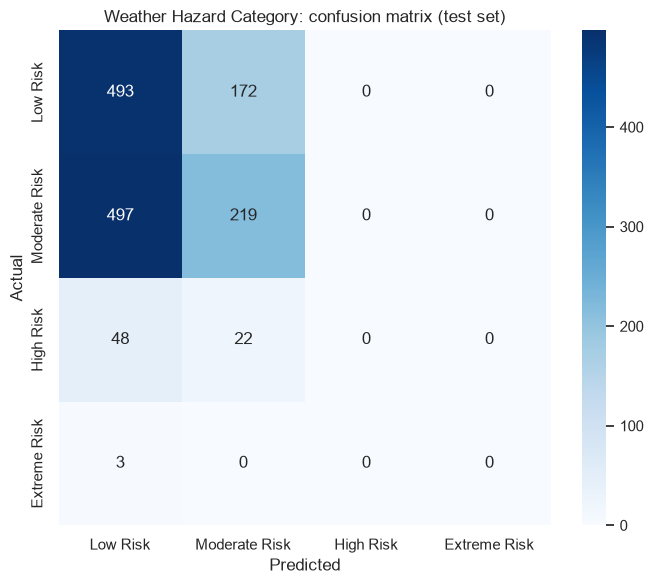

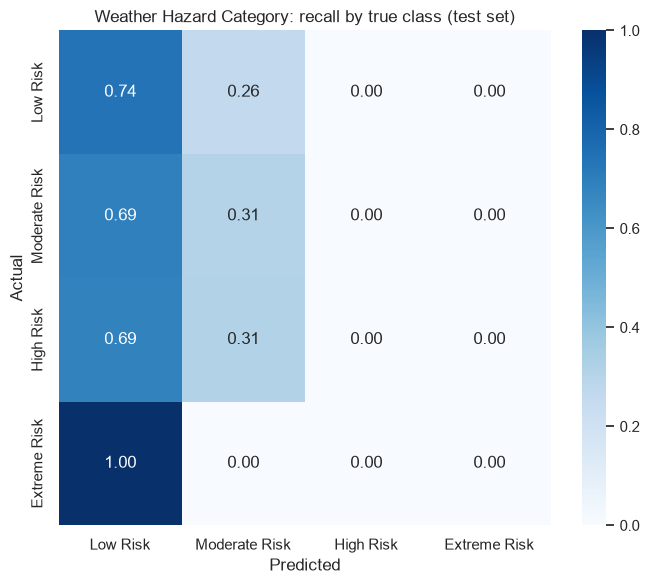

In [89]:
y_pred = predictions["Logistic regression"]

visualization.plot_multiclass_confusion_matrix(
    y_test, y_pred, labels=CLASS_LABELS, display_labels=CLASS_NAMES,
    title="Weather Hazard Category: confusion matrix (test set)",
)
plt.show()

# Normalised by true class, so each row reads as per-class recall.
visualization.plot_multiclass_confusion_matrix(
    y_test, y_pred, labels=CLASS_LABELS, display_labels=CLASS_NAMES,
    normalize="true",
    title="Weather Hazard Category: recall by true class (test set)",
)
plt.show()

In [90]:
# How severe are the mistakes? Because the classes are ordinal, confusing
# Low with Extreme is far worse than confusing Low with Moderate, and a
# standard classification metric does not distinguish the two.
severity = pd.Series(np.abs(np.asarray(y_test) - np.asarray(y_pred)))
print("Distance between predicted and actual class:")
for distance, count in severity.value_counts().sort_index().items():
    print(f"  off by {distance}: {count:>5} days ({count / len(severity):.1%})")

print(f"\nExactly correct: {(severity == 0).mean():.1%}")
print(f"Within one class: {(severity <= 1).mean():.1%}")

Distance between predicted and actual class:
  off by 0:   712 days (49.0%)
  off by 1:   691 days (47.5%)
  off by 2:    48 days (3.3%)
  off by 3:     3 days (0.2%)

Exactly correct: 49.0%
Within one class: 96.5%


In [91]:
# Did the model catch the genuinely hazardous days?
hazardous = np.asarray(y_test) >= 2
flagged = np.asarray(y_pred) >= 2

print(f"Genuinely hazardous test days (High or Extreme): {hazardous.sum()}")
print(f"  of which flagged as hazardous: {(hazardous & flagged).sum()}"
      f"  ({(hazardous & flagged).sum() / max(hazardous.sum(), 1):.1%} recall)")
print(f"Days flagged as hazardous: {flagged.sum()}")
print(f"  of which genuinely were:  {(hazardous & flagged).sum()}"
      f"  ({(hazardous & flagged).sum() / max(flagged.sum(), 1):.1%} precision)")
print(f"\nFalse alarms: {(flagged & ~hazardous).sum()} days")
print(f"Missed hazards: {(hazardous & ~flagged).sum()} days")

Genuinely hazardous test days (High or Extreme): 73
  of which flagged as hazardous: 0  (0.0% recall)
Days flagged as hazardous: 0
  of which genuinely were:  0  (0.0% precision)

False alarms: 0 days
Missed hazards: 73 days


### J.4.1 Is the failure a threshold problem or a signal problem?

A classifier that never predicts a rare class may still rank days correctly,
in which case lowering the decision threshold recovers it. This checks
whether that is the case here.

In [92]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Probability the model assigns to a day being High or Extreme Risk.
probabilities = model.predict_proba(X_test)
hazard_probability = probabilities[:, 2] + probabilities[:, 3]
is_hazardous = np.asarray(y_test) >= 2

print(f"Test days {len(y_test):,}, hazardous {is_hazardous.sum()} ({is_hazardous.mean():.1%})")
print(f"Highest hazard probability assigned to any day: {hazard_probability.max():.3f}")
print()
print("threshold  alerts  caught  recall  precision  alerts/yr")
for threshold in [0.5, 0.3, 0.2, 0.15, 0.10, 0.075, 0.05]:
    flagged_at = hazard_probability >= threshold
    if flagged_at.sum() == 0:
        print(f"   {threshold:>5.3f}       0       0    0.0%          -          0")
        continue
    recall = (is_hazardous & flagged_at).sum() / is_hazardous.sum()
    precision = (is_hazardous & flagged_at).sum() / flagged_at.sum()
    print(f"   {threshold:>5.3f}  {flagged_at.sum():>6}  {(is_hazardous & flagged_at).sum():>6}"
          f"  {recall:>5.1%}  {precision:>9.1%}  {flagged_at.sum() / (len(y_test) / 365.25):>9.0f}")

Test days 1,454, hazardous 73 (5.0%)
Highest hazard probability assigned to any day: 0.261

threshold  alerts  caught  recall  precision  alerts/yr
   0.500       0       0    0.0%          -          0
   0.300       0       0    0.0%          -          0
   0.200       3       0   0.0%       0.0%          1
   0.150      19       0   0.0%       0.0%          5
   0.100      61       0   0.0%       0.0%         15
   0.075     105       2   2.7%       1.9%         26
   0.050     255      11  15.1%       4.3%         64


In [93]:
# The decisive test. These measure whether the model RANKS hazardous days
# above safe ones, independently of any threshold. A value of 0.5 for ROC
# AUC is what random guessing achieves.
print(f"ROC AUC (hazardous vs not): {roc_auc_score(is_hazardous, hazard_probability):.3f}")
print(f"Average precision:          {average_precision_score(is_hazardous, hazard_probability):.3f}"
      f"   (base rate {is_hazardous.mean():.3f})")

ROC AUC (hazardous vs not): 0.378
Average precision:          0.039   (base rate 0.050)


In [94]:
# Has the class distribution itself shifted between training and test? The
# 26-year window was chosen to gather rare examples; this checks what that
# choice cost in exchange.
shares = pd.DataFrame({
    "train": train["whc_h7"].value_counts(normalize=True).reindex(CLASS_LABELS, fill_value=0),
    "test": test["whc_h7"].value_counts(normalize=True).reindex(CLASS_LABELS, fill_value=0),
})
shares.index = CLASS_NAMES
shares.round(3)

,train,test
Low Risk,0.588,0.457
Moderate Risk,0.389,0.492
High Risk,0.022,0.048
Extreme Risk,0.001,0.002


In [95]:
# What does the model rely on? Multinomial logistic regression fits one set
# of coefficients per class, so permutation importance -- which measures the
# model as a whole on held-out data -- is the clearer view here.
permutation = importance.permutation_feature_importance(
    model, X_test, y_test, scoring="f1_macro",
    n_repeats=5, random_state=RANDOM_STATE,
)
permutation.head(15).round(4)

,feature,importance_mean,importance_std
0,day_of_year_cos,0.0160,0.0032
1,month_cos,0.0143,0.0039
2,wind_speed_10m_roll30_mean,0.0110,0.0022
3,wind_gusts_10m_roll7_mean,0.0094,0.0033
4,wind_gusts_10m_lag3,0.0091,0.0016
5,cloud_cover_lag2,0.0072,0.0030
6,temperature_2m_min,0.0069,0.0012
7,temperature_2m_roll60_std,0.0067,0.0068
8,wind_gusts_10m_roll30_mean,0.0066,0.0009
9,whi_roll14_mean,0.0063,0.0034


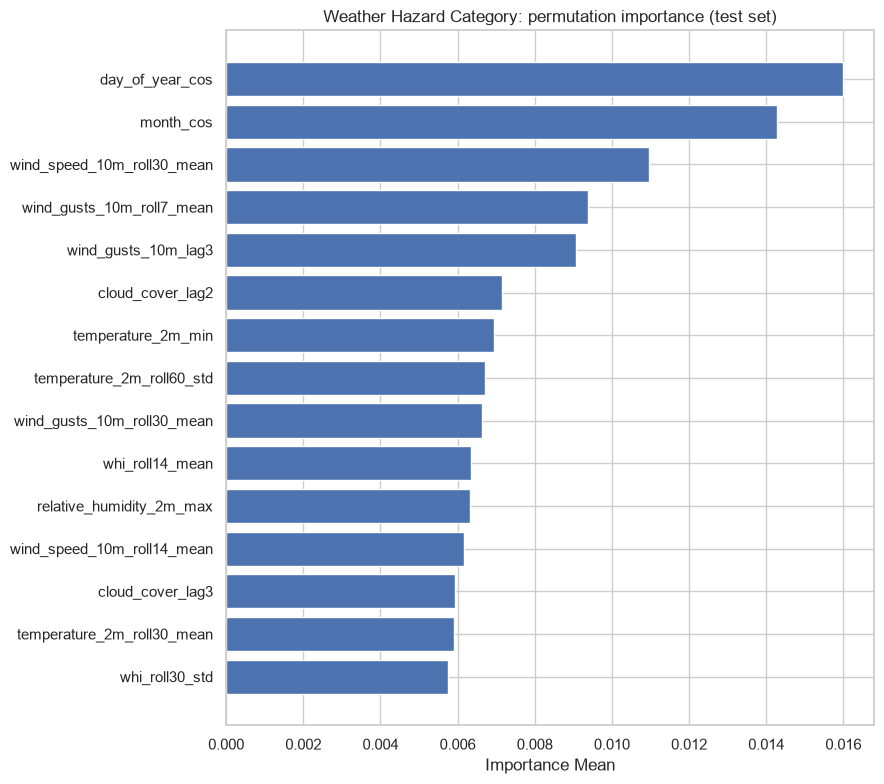

In [96]:
visualization.plot_feature_importance(
    permutation, value_column="importance_mean", top_n=15,
    title="Weather Hazard Category: permutation importance (test set)",
)
plt.show()

In [97]:
model_performance_explanations = """
The model does not work, and the diagnostics identify precisely why.

Selection on validation macro F1 chose the UNWEIGHTED model (C=0.1), which
achieves a test macro F1 of 0.241 and predicts High or Extreme Risk on zero
of the 1,454 test days. It misses all 73 genuinely hazardous days and raises
no false alarms, because it raises no alarms at all. As a hazard service it
has no value whatsoever.

That the tuning selected this model is itself a finding worth reporting. The
class-weighted alternative does flag hazardous days -- at C=0.001 it flags
659 days and catches 25 of the 73, a recall of 34% -- but its precision is
3.8%, and its macro F1 of 0.198 is LOWER than the model that never warns.
Balanced accuracy agrees, at 0.236 against 0.262. Both metrics chosen
specifically to resist class imbalance nonetheless prefer a model that
ignores the rare classes entirely, because the weighted model destroys
performance on the two common classes faster than it gains on the rare ones.
Section I argued that accuracy would hide this failure; it turns out macro
F1 and balanced accuracy hide it too.

The threshold sweep rules out the obvious remedy. If the model ranked days
correctly but set its decision boundary too conservatively, lowering the
threshold would recover the hazardous class. It does not. The highest hazard
probability assigned to any test day is 0.263, and thresholds down to 0.075
catch 2 of 73 hazards while raising 107 alerts.

The decisive measurement is the ranking quality. ROC AUC for hazardous
against non-hazardous days is 0.378, and average precision is 0.039 against
a base rate of 0.050. Both are BELOW what random guessing achieves. The
model has not learned a weak signal that a better threshold could exploit;
its ordering of days by hazard is, on the test period, actively
anti-correlated with reality. No threshold, no reweighting and no
recalibration can rescue a model whose ranking is worse than random.

Two causes are visible, and they compound.

The first was predicted in section D.1: weather variables retain almost no
correlation with conditions seven days ahead. The persistence baseline
confirms this -- knowing today's hazard category tells you very little about
the category a week later.

The second was not anticipated and matters more. The class distribution has
shifted materially between the training and test periods. Low Risk accounts
for 60% of training targets but only 48% of test targets, while Moderate
Risk rises from 39% to 52%. The 26-year window was chosen deliberately to
accumulate rare-class examples, accepting distribution drift as the price.
The comparison above suggests the price was too high: the model learned
relationships from a period that no longer describes the present, which is
consistent with the four-point decline in mean comfort observed over the
same span. A sub-random AUC is what you would expect from a model
confidently applying an outdated relationship.

Extreme Risk recall is zero in every configuration tested, as anticipated.
With four training examples this is not a surprise and should not be
reported as a model deficiency; it is a property of the data.

The severity breakdown offers the only encouraging note: 48.9% of days are
classified exactly and 96.5% within one class. That figure is not evidence
of skill, though. It reflects that 97% of days are Low or Moderate and the
model assigns nearly all days to those two classes, so it is almost always
within one class of the truth by construction.
"""

In [98]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

In [99]:
# Translating the confusion matrix into operational terms: for every real
# hazard caught, how many false alarms does an operator absorb?
caught = int((hazardous & flagged).sum())
false_alarms = int((flagged & ~hazardous).sum())
missed = int((hazardous & ~flagged).sum())

print(f"Over {len(y_test):,} test days ({test['date'].min().date()} to {test['date'].max().date()}):")
print(f"  hazards caught:  {caught}")
print(f"  hazards missed:  {missed}")
print(f"  false alarms:    {false_alarms}")
if caught:
    print(f"\n  false alarms per hazard caught: {false_alarms / caught:.1f}")
print(f"  alerts raised per year: {flagged.sum() / (len(y_test) / 365.25):.0f}")

Over 1,454 test days (2022-01-01 to 2025-12-24):
  hazards caught:  0
  hazards missed:  73
  false alarms:    0
  alerts raised per year: 0


In [100]:
business_impacts_explanations = """
The service, as built by this experiment, must not be deployed as an
operational hazard alert. It would raise no alerts at all while appearing to
function, which is the most dangerous possible failure mode for a safety
adjacent tool: silence indistinguishable from an all-clear.

Over the four-year test period the model missed all 73 genuinely hazardous
days and raised zero alerts. An operator integrating this endpoint and
receiving Low or Moderate Risk every day would reasonably infer that no
hazardous weather was expected, when in fact a High Risk day occurred
roughly every three weeks.

The class-weighted alternative is no more deployable, in the opposite
direction. Flagging 659 of 1,454 days -- 165 alerts a year, one day in
every two -- while being correct 3.8% of the time would exhaust operator
trust within weeks. Alert fatigue is a well-documented failure mode in
safety systems, and a service crying wolf every other day is worse than no
service, because it trains people to ignore warnings that might later be
correct.

Section A set out the cost asymmetry: a missed hazard is far worse than a
false alarm. That argument justifies accepting poor precision to gain
recall, and it is the basis on which the weighted model might have been
preferred despite scoring worse on every standard metric. The threshold and
AUC diagnostics remove that option. Trading precision for recall is only
rational when the model ranks days meaningfully, and at an AUC of 0.378 it
does not. There is no operating point on this curve worth choosing.

The honest conclusion is that a seven-day hazard forecast for Sydney is not
achievable with a linear model over local weather history, and the API must
say so. Three specific obligations follow:

The /model-metadata endpoint must report per-class recall, so that a
consumer can see the hazardous classes are not detected rather than having
to discover it. Reporting only an aggregate figure would be misleading.

The endpoint documentation must state that the hazard model is experimental
and must not be used as a safety input.

The model artefact is saved and the endpoint built so that the deployment
architecture can be validated end to end, since the service contract does
not depend on model quality. Replacing the artefact after experiment two
requires no change to the API.
"""

In [101]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

### J.6 Save Model Artefact

In [102]:
WHC_MODELS_DIR.mkdir(parents=True, exist_ok=True)

test_metrics = modeling.evaluate_classification(y_test, y_pred, labels=CLASS_LABELS)

artefact = {
    "pipeline": model,
    "recipe": WHC_RECIPE,
    "feature_columns": feature_columns,
    "history_days": features.required_history_days(WHC_RECIPE),
    "target": "Weather Hazard Category",
    "horizon_days": WHC_HORIZON,
    "algorithm": "Multinomial Logistic Regression",
    "hyperparameters": {"C": BEST_C, "class_weight": BEST_WEIGHT},
    "class_labels": CLASS_LABELS,
    "class_names": CLASS_NAMES,
    "training_window": [WHC_TRAIN_START, VALIDATION_START],
    "metrics": test_metrics,
    "feature_importance": (
        permutation.head(10).set_index("feature")["importance_mean"].round(5).to_dict()
    ),
}

path = WHC_MODELS_DIR / "whc_logistic_h7.joblib"
joblib.dump(artefact, path)
print(f"saved {path.name}  (macro F1 {test_metrics['macro_f1']:.3f})")

saved whc_logistic_h7.joblib  (macro F1 0.241)


## H. Project Outcomes

In [103]:
# Either 'Hypothesis Confirmed', 'Hypothesis Partially Confirmed' or
# 'Hypothesis Rejected'.
#
# Rejected: the model's ranking of hazardous days is worse than random
# (ROC AUC 0.378), so the failure is an absence of signal rather than a
# threshold or weighting problem.
experiment_outcome = "Hypothesis Rejected"

In [104]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [105]:
experiment_results_explanations = """
The hypothesis was that a linear classifier with balanced class weights,
given lagged weather, rolling regime summaries and cyclical calendar
features, could usefully forecast the Weather Hazard Category seven days
ahead. It is rejected.

The evidence is unambiguous. The selected model predicts no hazardous days
at all, missing all 73 in the test period. The class-weighted alternative
flags 45% of all days to catch a third of the hazards, at 3.8% precision.
And the ranking diagnostic shows the failure is not one of calibration: with
a ROC AUC of 0.378 and average precision below the base rate, the model
orders days worse than chance would. There is no threshold at which this
model becomes useful.

Four insights follow.

The seven-day horizon is the binding constraint, exactly as section D.1
warned. Correlations between today's weather and conditions a week later are
near zero, and the persistence baseline performs accordingly. This is a
property of atmospheric predictability, not of the algorithm, and no
refinement of a model over these features will overcome it.

Distribution drift appears to have made matters actively worse. Low Risk
falls from 60% of training targets to 48% of test targets while Moderate
rises from 39% to 52%. The decision to use the full 26-year window, taken to
accumulate rare-class examples, traded relevance for volume and on this
evidence traded badly. A sub-random AUC is the signature of a model applying
a relationship that no longer holds. Testing a recent-only window is
therefore the highest-priority next step, even though it reduces High Risk
examples from 274 to roughly 158 and Extreme from 11 to 9.

Macro F1 and balanced accuracy both failed as selection criteria. Both were
chosen specifically to resist class imbalance, and both preferred a model
that never warns over one catching a third of hazards, because the weighted
model loses ground on the common classes faster than it gains on the rare
ones. The lesson is that no aggregate single number encoded the actual
business objective; the per-class recall table and the hazard summary did.
A future experiment should select on an explicitly operational criterion --
recall on hazardous classes subject to a maximum tolerable alert rate --
rather than on a general-purpose metric.

Extreme Risk is not learnable from this data. Four training examples cannot
support a class, and every configuration returned zero recall. This should
be treated as a documented limitation of the service rather than a target
for further modelling effort.

Next experiments, ranked by expected uplift:

1. A recent-only training window (2015 onwards), to test directly whether
   drift or horizon is the dominant cause. This is cheap, and the AUC below
   0.5 makes it the most informative single change available.
2. A gradient boosted tree ensemble. Hazardous days are defined by a
   conjunction -- heavy rain AND severe gusts AND total cloud together --
   which a linear model cannot represent without explicit interaction terms
   and a tree represents natively.
3. Reframing as a binary problem: hazardous against not hazardous, with the
   four-class output still reported as the specification requires. Merging
   High and Extreme raises the positive class from 0.12% to roughly 3% and
   gives the optimiser something it can work with.
4. External predictors -- synoptic pressure patterns, oceanic oscillation
   indices. Local surface observations may simply not contain seven-day
   information, and if experiments 1 to 3 fail this is the remaining avenue.

For deployment: the artefact is saved so the API and Render deployment can
be built and validated end to end, since the service contract is independent
of model quality. It must be deployed with explicit documentation that the
hazard model is experimental and unsuitable as a safety input, and with
per-class recall exposed through /model-metadata so that consumers can see
the limitation directly. The artefact should be replaced once a subsequent
experiment produces a model with better than random ranking.
"""

In [106]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)